# 강남구 무더위쉼터 입지 분석

기존 쉼터 98곳을 그대로 두고 신규 쉼터 p곳을 어디에 둘지 세 모형으로 푼다.
계산 흐름은 금천구 노트북(`금천구/분석/금천구무더위쉼터입지분석3가지.ipynb`)을 따르고, 그림은 서울 EDA(`3_분석/seoul_eda.ipynb`)와 같은 색과 형식으로 그린다.

**지금 저장된 그림은 모의 유동인구로 그린 것이다.** 값이 난수라서 그림의 모양만 확인할 수 있고 해석하면 안 된다.
안심구역에서는 `0. 설정`의 `SAFE_ZONE`을 `True`로 바꾸고 경로를 확인한 뒤 다시 실행한다.
그림에는 제목을 넣지 않았다. 보고서에서 캡션으로 붙인다.

- MCLP: 기준거리 안에 들어오는 60대 이상 유동인구를 최대화한다.
- 형평성 MCLP: 행정동별 커버율의 최솟값을 최대화한다. 전체 커버 인구는 MCLP 최적값의 η 이상을 유지한다.
- p-median: 가장 가까운 쉼터까지의 인구가중 보행거리 합을 최소화한다.

p를 1부터 `P_MAX`까지 바꿔 가며 세 모형을 모두 풀고, 지도는 `P_MAP` 하나에서 그린다.

1. 자료 불러오기
2. 보행 네트워크와 스냅
3. 거리 계산과 기존 쉼터 접근성
4. 세 모형 풀기 (p = 1 ~ P_MAX)
5. p에 따른 커버율 증가폭과 P_MAP
6. 모형별 선정 입지 지도
7. 세 모형 공통 선정 입지
8. p별 선정 후보지
9. p별 커버율, 최저 행정동 커버율, 평균 보행거리
10. 결과 저장

데이터 행을 그대로 출력하는 셀은 없다. 출력은 건수, 강남구와 행정동 단위 집계, 후보시설 목록, 그림뿐이다.

In [1]:
import time
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager
from matplotlib.lines import Line2D
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import coo_matrix
from scipy.spatial import cKDTree
from shapely import wkt
from shapely.geometry import Point

warnings.filterwarnings("ignore", category=UserWarning)

# 한글 글꼴. 설치된 것 중 먼저 찾은 것을 쓴다.
installed = {f.name for f in font_manager.fontManager.ttflist}
for font_name in ["Malgun Gothic", "NanumGothic", "NanumBarunGothic", "AppleGothic"]:
    if font_name in installed:
        plt.rcParams["font.family"] = font_name
        break
else:
    print("한글 글꼴을 찾지 못했다. 그림의 한글이 깨지면 font_name 목록에 설치된 글꼴 이름을 추가한다.")
plt.rcParams["axes.unicode_minus"] = False

# 색. 서울 EDA와 같은 값이다. 같은 역할에는 같은 색을 쓴다.
INK, INK_SUB, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, LAND, BORDER, GRID = "#fcfcfb", "#f3f2ee", "#c3c2b7", "#e1e0d9"
BLUE = "#2a78d6"     # 기본 계열. 모형 그림에서는 MCLP
ORANGE = "#eb6834"   # 강조. 모형 그림에서는 형평성 MCLP, 공통 입지 지도에서는 신규 선정
AQUA = "#1baf7a"     # 세 번째 계열. 모형 그림에서는 p-median
GRAY = "#b5b3aa"     # 배경 역할
ORANGE_RAMP = ["#f6bfa6", "#eb6834", "#a83c12"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BORDER, "axes.labelcolor": INK_SUB, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_SUB, "axes.titlelocation": "left",
})

## 0. 설정

In [2]:
SAFE_ZONE = True     # 데이터안심구역에서 실행할 때 True로 바꾼다



if SAFE_ZONE:
    # 안심구역 내 경로. 실제 폴더 이름과 다르면 이 네 줄만 고친다.
    FLOW_PATH = Path("upload/GangnamPopulation7to9.csv") 
    FLOW_SEP = ","
    INPUT = Path("upload")            # 반입한 강남구 경계, 쉼터, 후보시설, 네트워크 파일
    OUT = Path("gangnam_output")      # 그림과 표가 저장될 폴더
    
else:
    # 로컬. 유동인구는 강남구만 잘라 둔 모의 자료를 읽는다.
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "강남구_데이터").exists())
    INPUT = ROOT / "강남구_데이터" / "데이터"
    FLOW_PATH = INPUT / "GangnamPopulation.csv"
    FLOW_SEP = ","
    OUT = ROOT / "강남구" / "결과" / "모형"

BOUNDARY_PATH = INPUT / "GangnamBoundary.shp"         # 행정동 22개
SHELTER_PATH = INPUT / "GangnamCoolingCenter.csv"     # 기존 쉼터
CANDIDATE_PATH = INPUT / "GangnamCandidateFacility.csv"
NETWORK_PATH = INPUT / "GangnamNetwork.csv"           # 강남구 경계에서 자른 보행 네트워크


COVERAGE_DISTANCE_M = 219      # 서울 EDA, Seoul.ipynb와 같은 값. 여기서는 보행 네트워크 거리
P_MAX = 40                     # p를 1부터 여기까지 푼다
P_TABLE = list(range(5, P_MAX + 1, 5))   # 표로 비교할 p
P_MAP = None                   # 지도에 쓸 p. None이면 5절의 규칙으로 정한다
MARGINAL_PP = 0.5              # 다섯 곳 구간의 한 곳당 평균 MCLP 커버율 증가(%p)가 이 값 이상인 마지막 p를 쓴다
ETA = 0.95                     # 형평성 MCLP가 지킬 MCLP 최적 커버 인구의 비율
EQUITY_TIEBREAK = True         # 최저 동 커버율이 같은 해가 여럿이면 전체 커버율이 가장 높은 해를 고른다
SNAP_CHECK_M = 100             # 네트워크 노드까지 이보다 멀리 스냅된 점의 수를 보고한다
TIME_LIMIT_S = 120             # 모형 하나를 푸는 시간 상한 (초)

AGE60_COLS = ["MAN_FLOW_POP_CNT_60GU", "WMAN_FLOW_POP_CNT_60GU"]
MODELS = ["MCLP", "형평성 MCLP", "p-median"]
MODEL_COLOR = {"MCLP": BLUE, "형평성 MCLP": ORANGE, "p-median": AQUA}
MODEL_FILE = {"MCLP": "MCLP", "형평성 MCLP": "형평성MCLP", "p-median": "p-median"}

SAVE = True
OUT.mkdir(parents=True, exist_ok=True)

# 파일이 제자리에 있는지 먼저 확인한다. 없는 파일이 있으면 여기서 멈춘다.
shp_parts = [BOUNDARY_PATH.with_suffix(s) for s in (".shx", ".dbf", ".prj")]
missing = [str(f) for f in (FLOW_PATH, BOUNDARY_PATH, *shp_parts, SHELTER_PATH, CANDIDATE_PATH, NETWORK_PATH)
           if not f.exists()]
if missing:
    raise FileNotFoundError("다음 파일을 찾을 수 없다: " + ", ".join(missing))
print("입력 파일 확인")

입력 파일 확인


## 0-1. 보조 함수

In [3]:
def save(fig, name):
    if SAVE:
        fig.savefig(OUT / name, dpi=200, bbox_inches="tight")


def clean(ax, grid="x"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def legend_top(ax, handles):
    ax.legend(handles=handles, frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0),
              ncol=len(handles), fontsize=9, labelcolor=INK_SUB, borderaxespad=0.2)


def read_csv_any(path, **kw):
    for enc in ("utf-8-sig", "cp949"):
        try:
            return pd.read_csv(path, encoding=enc, **kw)
        except UnicodeDecodeError:
            continue
    raise UnicodeDecodeError(f"{path}를 utf-8, cp949 어느 쪽으로도 읽지 못했다")


def read_points(path):
    df = read_csv_any(path)
    n_raw = len(df)
    df = df.dropna(subset=["경도", "위도"]).reset_index(drop=True)
    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["경도"], df["위도"]), crs=4326).to_crs(5179)
    return gdf, n_raw - len(df)


def snap(points, tree, node_ids):
    dist, idx = tree.query(np.column_stack([points.geometry.x, points.geometry.y]))
    out = points.copy()
    out["node"] = node_ids[idx]
    out["snap_m"] = dist
    return out


def weighted_mean(values, weights):
    values, weights = np.asarray(values, float), np.asarray(weights, float)
    ok = np.isfinite(values) & (weights > 0)
    return np.average(values[ok], weights=weights[ok])


def base_map(ax):
    dong.plot(ax=ax, facecolor=LAND, edgecolor=BORDER, linewidth=0.6, zorder=1)
    ax.set_aspect("equal")
    ax.set_axis_off()


def dong_labels(ax):
    for name, pt in zip(dong["dong"], dong.representative_point()):
        ax.text(pt.x, pt.y, name, fontsize=7, color=INK_MUTED, ha="center", va="center", zorder=4.5,
                path_effects=[pe.withStroke(linewidth=2.2, foreground=LAND)])


def context_layers(ax):
    """모든 입지 지도에 공통으로 깔리는 층. 행정동, 후보시설, 기존 쉼터."""
    base_map(ax)
    dong_labels(ax)
    ax.scatter(cand_clean.geometry.x, cand_clean.geometry.y, s=14, facecolors="none",
               edgecolors=GRAY, linewidths=0.8, zorder=4)
    # 기존 쉼터는 회색으로 칠한다. 파랑은 MCLP 선정지 색이라 겹치지 않게 한다.
    ax.scatter(existing_clean.geometry.x, existing_clean.geometry.y, s=22, color=INK_MUTED,
               edgecolors=SURFACE, linewidths=0.8, zorder=5)


def context_handles():
    return [
        Line2D([], [], marker="o", linestyle="", markersize=6, color=INK_MUTED, label=f"기존 쉼터 ({len(existing_clean)}곳)"),
        Line2D([], [], marker="o", linestyle="", markersize=6, markerfacecolor="none",
               markeredgecolor=GRAY, label=f"후보시설 ({len(cand_clean)}곳)"),
    ]


def spread(values, min_gap):
    """끝 라벨이 겹치지 않게 y 위치를 min_gap 이상 벌린다. 순서는 유지한다."""
    order = np.argsort(values)
    pos = np.asarray(values, float)[order].copy()
    for _ in range(50):
        for k in range(1, len(pos)):
            if pos[k] - pos[k - 1] < min_gap:
                mid = (pos[k] + pos[k - 1]) / 2
                pos[k - 1], pos[k] = mid - min_gap / 2, mid + min_gap / 2
    out = np.empty_like(pos)
    out[order] = pos
    return out

## 1. 자료 불러오기

60대 이상 유동인구(남녀 합)를 수요로 쓴다. 격자에 행정동을 붙이고 강남구 밖 격자는 버린다.
기존 쉼터는 강남구 98곳만 쓴다. 경계 밖 쉼터는 넣지 않았으므로 경계부 수요지의 커버율은 실제보다 낮게 나올 수 있다.

In [4]:
dong = gpd.read_file(BOUNDARY_PATH).to_crs(5179).rename(columns={"ADM_NM": "dong"})[["dong", "geometry"]]

flow = pd.read_csv(FLOW_PATH, sep=FLOW_SEP)
flow = gpd.GeoDataFrame(flow, geometry=gpd.points_from_xy(flow["X_COORD"], flow["Y_COORD"]), crs=5179)
flow = flow.rename(columns={"ADM_NM": "dong"})

n_flow = len(flow)

existing, n_shelter_drop = read_points(SHELTER_PATH)
cand, n_cand_drop = read_points(CANDIDATE_PATH)

print("행정동:", f"{len(dong)}개")
print("유동인구 격자:", f"{n_flow:,}개 중 강남구 안, 가중치 0 초과 {len(flow):,}개")
print("기존 쉼터:", f"{len(existing)}곳 (좌표 없음 {n_shelter_drop}곳)")
print("후보시설:", f"{len(cand)}곳 (좌표 없음 {n_cand_drop}곳)")

행정동: 22개
유동인구 격자: 15,332개 중 강남구 안, 가중치 0 초과 15,332개
기존 쉼터: 98곳 (좌표 없음 0곳)
후보시설: 151곳 (좌표 없음 1곳)


## 2. 보행 네트워크와 스냅

링크 길이를 가중치로 그래프를 만들고 가장 큰 연결요소만 쓴다.
네트워크가 강남구 경계에서 잘려 있어서 잘린 링크의 끝점에는 NODE 행이 없다. 그 좌표는 링크 WKT의 첫 점과 끝 점으로 채운다.
수요 격자, 기존 쉼터, 후보시설은 가장 가까운 노드에 붙인다.

In [5]:
net = read_csv_any(NETWORK_PATH, dtype=str, low_memory=False)

links = net[net["노드링크 유형"] == "LINK"].copy()
links["length"] = pd.to_numeric(links["링크 길이"], errors="coerce")
links = links[np.isfinite(links["length"]) & (links["length"] > 0)]

node_rows = net[(net["노드링크 유형"] == "NODE") & net["노드 WKT"].notna()]
node_pt = dict(zip(node_rows["노드 ID"], node_rows["노드 WKT"].map(wkt.loads)))

n_recovered = 0
for s, e, g in zip(links["시작노드 ID"], links["종료노드 ID"], links["링크 WKT"]):
    if (s in node_pt and e in node_pt) or not isinstance(g, str):
        continue
    line = wkt.loads(g)
    parts = list(line.geoms) if line.geom_type == "MultiLineString" else [line]
    if s not in node_pt:
        node_pt[s] = Point(parts[0].coords[0])
        n_recovered += 1
    if e not in node_pt:
        node_pt[e] = Point(parts[-1].coords[-1])
        n_recovered += 1

G = nx.Graph()
for u, v, length in zip(links["시작노드 ID"], links["종료노드 ID"], links["length"]):
    if u == v:
        continue
    if not G.has_edge(u, v) or length < G[u][v]["length"]:
        G.add_edge(u, v, length=float(length))
n_graph_all = G.number_of_nodes()
G = G.subgraph(max(nx.connected_components(G), key=len)).copy()

node_ids = np.array([n for n in G.nodes if n in node_pt])
node_geo = gpd.GeoSeries([node_pt[n] for n in node_ids], crs=4326).to_crs(5179)
tree = cKDTree(np.column_stack([node_geo.x, node_geo.y]))

flow = snap(flow, tree, node_ids)
existing = snap(existing, tree, node_ids)
cand = snap(cand, tree, node_ids)

print("링크:", f"{len(links):,}개, 좌표를 복원한 노드 {n_recovered}개")
print("그래프 노드:", f"{n_graph_all:,}개 중 가장 큰 연결요소 {G.number_of_nodes():,}개 "
      f"({G.number_of_nodes() / n_graph_all * 100:.1f}%)")
for label, pts in [("수요 격자", flow), ("기존 쉼터", existing), ("후보시설", cand)]:
    print(f"{label} 스냅 거리: 중앙값 {pts['snap_m'].median():.1f}m, 최대 {pts['snap_m'].max():.0f}m, "
          f"{SNAP_CHECK_M}m 초과 {(pts['snap_m'] > SNAP_CHECK_M).sum()}개")

링크: 16,949개, 좌표를 복원한 노드 322개
그래프 노드: 12,590개 중 가장 큰 연결요소 12,467개 (99.0%)
수요 격자 스냅 거리: 중앙값 31.8m, 최대 738m, 100m 초과 2514개
기존 쉼터 스냅 거리: 중앙값 26.1m, 최대 82m, 100m 초과 0개
후보시설 스냅 거리: 중앙값 21.9m, 최대 157m, 100m 초과 2개


## 2-1. 분석용 수요지, 기존 쉼터, 후보지

- 같은 노드에 붙은 수요 격자는 가중치를 더한다. 행정동이 다르면 따로 둔다.
- 같은 노드에 붙은 후보시설은 하나만 남긴다.
- 기존 쉼터와 같은 노드에 붙은 후보시설은 뺀다.

In [6]:
existing_clean = existing.drop_duplicates("node").copy()
existing_nodes = existing_clean["node"].tolist()

cand_clean = (cand.sort_values("snap_m").drop_duplicates("node")
              .loc[lambda d: ~d["node"].isin(existing_nodes)].sort_index().reset_index(drop=True))
cand_clean["candidate_id"] = [f"C{i:03d}" for i in range(1, len(cand_clean) + 1)]
cand_clean["label"] = cand_clean["candidate_id"] + " " + cand_clean["시설명"].astype(str)

demand = flow.groupby(["node", "dong"], as_index=False).agg(weight=("weight", "sum"), n_grid=("weight", "size"))
w = demand["weight"].to_numpy(float)
dong_of = demand["dong"].to_numpy()
pop_dong = pd.Series(w).groupby(dong_of).sum()
n_cand = len(cand_clean)

print("기존 쉼터:", f"{len(existing)}곳 → 노드 기준 {len(existing_clean)}곳")
print("후보지:", f"{len(cand)}곳 → 중복 노드, 기존 쉼터 노드 제외 후 {n_cand}곳")
print("수요지:", f"격자 {len(flow):,}개 → 노드 기준 {len(demand):,}개, 행정동 {demand['dong'].nunique()}개")

기존 쉼터: 98곳 → 노드 기준 96곳
후보지: 151곳 → 중복 노드, 기존 쉼터 노드 제외 후 148곳
수요지: 격자 15,332개 → 노드 기준 8,346개, 행정동 22개


In [7]:
cand_clean.info()

# node = network_node
# snap_m = snap_distance_m

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   시설유형          148 non-null    object  
 1   시설명           148 non-null    object  
 2   시구동           148 non-null    object  
 3   시설수           148 non-null    int64   
 4   상세주소          148 non-null    object  
 5   위도            148 non-null    float64 
 6   경도            148 non-null    float64 
 7   좌표출처          148 non-null    object  
 8   geometry      148 non-null    geometry
 9   node          148 non-null    object  
 10  snap_m        148 non-null    float64 
 11  candidate_id  148 non-null    object  
 12  label         148 non-null    object  
dtypes: float64(3), geometry(1), int64(1), object(8)
memory usage: 15.2+ KB


## 3. 거리 계산과 기존 쉼터 접근성

기존 쉼터까지 거리는 다중 출발점 다익스트라로 한 번에 구한다.
후보지까지 거리는 후보지마다 다익스트라를 돌린다. 기존 쉼터 최대 거리보다 먼 값은 어느 모형에도 쓰이지 않으므로 거기서 끊는다.

In [8]:
near = nx.multi_source_dijkstra_path_length(G, existing_nodes, weight="length")

e = np.array([near.get(n, np.inf) for n in demand["node"]])


if not np.isfinite(e).all():
    raise RuntimeError("기존 쉼터에 닿지 않는 수요지가 있다. 네트워크 연결을 확인한다.")
cutoff = max(COVERAGE_DISTANCE_M, e.max())

rows_by_node = defaultdict(list)
for i, n in enumerate(demand["node"]):
    rows_by_node[n].append(i)

D = np.full((len(demand), n_cand), np.inf)
for j, src in enumerate(cand_clean["node"]):
    for n, d in nx.single_source_dijkstra_path_length(G, src, cutoff=cutoff, weight="length").items():
        for i in rows_by_node.get(n, ()):
            D[i, j] = d


def evaluate(selected):
    """선정 후보지 목록을 받아 세 지표를 계산한다. 기존 쉼터는 항상 포함한다."""
    dist = e if len(selected) == 0 else np.minimum(e, D[:, selected].min(axis=1))
    covered = dist <= COVERAGE_DISTANCE_M
    by_dong = pd.Series(w * covered).groupby(dong_of).sum() / pop_dong
    return {
        "coverage_pct": w[covered].sum() / w.sum() * 100,
        "min_dong_pct": by_dong.min() * 100,
        "mean_dist_m": weighted_mean(dist, w),
        "covered_people": w[covered].sum(),
    }


base = evaluate([])
print(f"기준거리 {COVERAGE_DISTANCE_M}m, 보행 네트워크 거리")
print(f"기존 쉼터 커버율: {base['coverage_pct']:.1f}%")
print(f"기존 최저 행정동 커버율: {base['min_dong_pct']:.1f}%")
print(f"기존 인구가중 평균 보행거리: {base['mean_dist_m']:.0f}m")

기준거리 219m, 보행 네트워크 거리
기존 쉼터 커버율: 22.8%
기존 최저 행정동 커버율: 4.0%
기존 인구가중 평균 보행거리: 407m


## 4. 세 모형 풀기

식은 금천구 노트북과 같다. p를 40번 바꿔 세 모형을 풀어야 해서 계산 방식만 세 가지 바꿨다. 셋 다 최적해를 바꾸지 않는다.

- 기준거리 안의 후보지 집합이 같은 수요지는 하나로 묶는다. 형평성 MCLP는 행정동까지 같아야 묶는다.
- 커버 변수 y는 0~1 연속변수로 둔다. y ≤ Σx 아래에서 최대화하므로 y는 0 또는 1이 된다. 형평성 MCLP의 y ≥ x 제약도 뺐다. 이 제약이 없으면 y가 실제보다 작게 잡힐 수는 있지만, 그 해에 실제 커버를 넣어도 모든 제약을 만족하므로 최적값과 선정 입지는 같다. 지표는 선정 결과로 다시 계산한다.
- 풀이기는 PuLP의 CBC 대신 scipy의 HiGHS를 쓴다.

형평성 MCLP는 최저 행정동 커버율이 기존 쉼터만으로 정해지는 동이 있으면 목적함수 값이 같은 해가 많아진다. `EQUITY_TIEBREAK = True`이면 최저 동 커버율을 최적값에 고정하고 전체 커버 인구를 한 번 더 최대화한다.

In [9]:
cover = np.isfinite(D) & (D <= COVERAGE_DISTANCE_M)
base_cov = e <= COVERAGE_DISTANCE_M
base_people = w[base_cov].sum()
open_rows = np.flatnonzero(~base_cov & cover.any(axis=1))   # 신규 쉼터로만 새로 커버될 수 있는 수요지


def group_rows(rows, by_dong=False):
    keys = [r.tobytes() for r in np.packbits(cover[rows], axis=1)]
    df = pd.DataFrame({"key": keys, "row": rows, "w": w[rows], "dong": dong_of[rows]})
    g = (df.groupby(["key", "dong"] if by_dong else ["key"], sort=False)
         .agg(w=("w", "sum"), first=("row", "first"), dong=("dong", "first")).reset_index(drop=True))
    g["cands"] = [np.flatnonzero(cover[i]) for i in g["first"]]
    return g


def link_matrix(groups, n_vars):
    """y_g - (g를 커버하는 후보지 x의 합) <= 0"""
    m = len(groups)
    r = np.concatenate([np.full(len(c), k) for k, c in enumerate(groups["cands"])])
    c = np.concatenate(groups["cands"].to_list())
    return coo_matrix((np.r_[-np.ones(len(r)), np.ones(m)], (np.r_[r, np.arange(m)], np.r_[c, n_cand + np.arange(m)])),
                      shape=(m, n_vars)).tocsr()


def run_milp(c, constraints, n_vars):
    integrality = np.r_[np.ones(n_cand), np.zeros(n_vars - n_cand)]
    res = milp(c, constraints=constraints, integrality=integrality, bounds=Bounds(0, 1),
               options={"time_limit": TIME_LIMIT_S, "mip_rel_gap": 1e-6})
    if res.x is None:
        raise RuntimeError(f"해를 찾지 못했다: {res.message}")
    if res.status != 0:
        print(f"  주의: {res.message}")
    return res


def p_row(n_vars):
    row = np.zeros(n_vars)
    row[:n_cand] = 1
    return row[None, :]


# MCLP
grp_m = group_rows(open_rows)
nv_m = n_cand + len(grp_m)
link_m = link_matrix(grp_m, nv_m)
c_m = np.r_[np.zeros(n_cand), -grp_m["w"].to_numpy()]


def solve_mclp(p):
    res = run_milp(c_m, [LinearConstraint(link_m, -np.inf, 0), LinearConstraint(p_row(nv_m), p, p)], nv_m)
    return np.flatnonzero(res.x[:n_cand] > 0.5)


# 형평성 MCLP. 변수 순서는 x, y, q
grp_e = group_rows(open_rows, by_dong=True)
nv_e = n_cand + len(grp_e) + 1
link_e = link_matrix(grp_e, nv_e)
dongs = pop_dong.index
base_dong = pd.Series(w * base_cov).groupby(dong_of).sum().reindex(dongs).to_numpy()
d_idx = dongs.get_indexer(grp_e["dong"])
dong_A = coo_matrix(
    (np.r_[grp_e["w"].to_numpy(), -pop_dong.to_numpy()],
     (np.r_[d_idx, np.arange(len(dongs))], np.r_[n_cand + np.arange(len(grp_e)), np.full(len(dongs), nv_e - 1)])),
    shape=(len(dongs), nv_e)).tocsr()
total_e = np.r_[np.zeros(n_cand), grp_e["w"].to_numpy(), 0.0]
q_row = np.zeros(nv_e)
q_row[-1] = 1


def solve_equity(p, mclp_people):
    cons = [LinearConstraint(link_e, -np.inf, 0),
            LinearConstraint(p_row(nv_e), p, p),
            LinearConstraint(dong_A, -base_dong, np.inf),                         # 동별 커버 인구 >= q x 동 인구
            LinearConstraint(total_e[None, :], ETA * mclp_people - base_people, np.inf)]
    res = run_milp(-q_row, cons, nv_e)
    if EQUITY_TIEBREAK:
        cons.append(LinearConstraint(q_row[None, :], res.x[-1] - 1e-7, np.inf))
        res = run_milp(-total_e, cons, nv_e)
    return np.flatnonzero(res.x[:n_cand] > 0.5)


# p-median. 기존 쉼터보다 가까운 후보지만 배정 대상으로 둔다. 변수 순서는 x, u, v
pi, pj = np.nonzero(np.isfinite(D) & (D < e[:, None]))
rows_pm = np.unique(pi)
ui = np.searchsorted(rows_pm, pi)
nu, nk = len(rows_pm), len(pi)
nv_p = n_cand + nu + nk
c_p = np.r_[np.zeros(n_cand), w[rows_pm] * e[rows_pm], w[pi] * D[pi, pj]]
assign = coo_matrix((np.ones(nu + nk), (np.r_[np.arange(nu), ui], np.r_[n_cand + np.arange(nu), n_cand + nu + np.arange(nk)])),
                    shape=(nu, nv_p)).tocsr()                                     # u_i + sum_k v_k = 1
opened = coo_matrix((np.r_[np.ones(nk), -np.ones(nk)], (np.r_[np.arange(nk), np.arange(nk)], np.r_[n_cand + nu + np.arange(nk), pj])),
                    shape=(nk, nv_p)).tocsr()                                     # v_k <= x_j


def solve_pmedian(p):
    cons = [LinearConstraint(assign, 1, 1), LinearConstraint(opened, -np.inf, 0), LinearConstraint(p_row(nv_p), p, p)]
    res = run_milp(c_p, cons, nv_p)
    return np.flatnonzero(res.x[:n_cand] > 0.5)


print(f"MCLP: 묶은 수요지 {len(grp_m):,}개 (원래 {len(open_rows):,}개)")
print(f"형평성 MCLP: 묶은 수요지 {len(grp_e):,}개")
print(f"p-median: 배정 쌍 {nk:,}개, 대상 수요지 {nu:,}개")

MCLP: 묶은 수요지 196개 (원래 1,779개)
형평성 MCLP: 묶은 수요지 232개
p-median: 배정 쌍 10,991개, 대상 수요지 4,774개


In [10]:
records = [{"model": m, "p": 0, **base} for m in MODELS]
selected = {}
t0 = time.time()
for p in range(1, P_MAX + 1):
    sel_m = solve_mclp(p)
    r_m = evaluate(sel_m)
    sel_e = solve_equity(p, r_m["covered_people"])
    sel_p = solve_pmedian(p)
    for model, sel in (("MCLP", sel_m), ("형평성 MCLP", sel_e), ("p-median", sel_p)):
        if len(sel) != p:
            raise RuntimeError(f"{model} p={p}: 선정 수가 {len(sel)}개다")
        selected[(model, p)] = sel
        records.append({"model": model, "p": p, **(r_m if model == "MCLP" else evaluate(sel))})
    if p % 5 == 0:
        print(f"p = {p:2d} 완료 ({time.time() - t0:.0f}초)")

metrics = pd.DataFrame(records)

p =  5 완료 (2초)
p = 10 완료 (5초)
p = 15 완료 (7초)
p = 20 완료 (8초)
p = 25 완료 (10초)
p = 30 완료 (12초)
p = 35 완료 (14초)
p = 40 완료 (15초)


## 5. p에 따른 커버율 증가폭

MCLP에서 p를 하나 늘릴 때 커버율이 몇 %p 오르는지 본다.
p는 1부터 모두 풀었지만 비교는 `P_TABLE`(5, 10, ..., 40)에서 한다. 한 곳씩 보면 증가폭이 들쭉날쭉해서 다섯 곳 단위 평균으로 판단한다.
p = 10이면 6~10번째 쉼터가 한 곳당 평균 몇 %p를 올렸는지 본다. 이 값이 `MARGINAL_PP` 이상인 마지막 p를 지도에 쓴다. `P_MAP`에 숫자를 넣으면 그 값을 쓴다.
아래 표는 `P_TABLE`의 p에서 세 모형을 비교한 것이다.

구간별 한 곳당 평균 커버율 증가 (%p): p=5 0.81, p=10 0.40, p=15 0.29, p=20 0.24, p=25 0.20, p=30 0.17, p=35 0.13, p=40 0.12


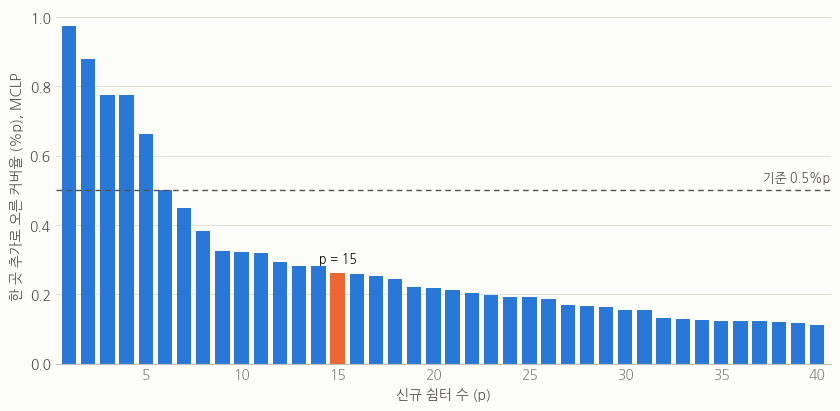

model,MCLP,형평성 MCLP,p-median
커버율(%) p=0,22.8,22.8,22.8
커버율(%) p=5,26.9,25.6,25.2
커버율(%) p=10,28.8,27.5,27.1
커버율(%) p=15,30.3,28.8,29.3
커버율(%) p=20,31.5,30.3,30.3
커버율(%) p=25,32.5,31.6,30.8
커버율(%) p=30,33.3,32.7,31.6
커버율(%) p=35,34.0,33.6,32.7
커버율(%) p=40,34.6,34.3,33.2
최저동커버율(%) p=0,4.0,4.0,4.0


In [11]:
cov_mclp = metrics[metrics["model"] == "MCLP"].set_index("p")["coverage_pct"]
gain = cov_mclp.diff().iloc[1:]          # gain[p]: p번째 쉼터가 더한 커버율 (%p)

# P_TABLE의 각 p에 대해, 직전 구간(예: p=10이면 6~10번째 쉼터)이 한 곳당 올린 평균 커버율
step = P_TABLE[0]
block_gain = pd.Series({p: (cov_mclp[p] - cov_mclp[p - step]) / step for p in P_TABLE})
print("구간별 한 곳당 평균 커버율 증가 (%p):", ", ".join(f"p={p} {v:.2f}" for p, v in block_gain.items()))

"""
if P_MAP is None:
    passed = block_gain[block_gain >= MARGINAL_PP]
    if len(passed):
        P_MAP = int(passed.index.max())
        print(f"P_MAP = {P_MAP} (한 곳당 평균 증가가 {MARGINAL_PP}%p 이상인 마지막 구간)")
    else:
        P_MAP = P_TABLE[0]
        print(f"P_MAP = {P_MAP}: 기준 {MARGINAL_PP}%p를 넘는 구간이 없어 가장 작은 p를 썼다. "
              "MARGINAL_PP를 낮추거나 P_MAP을 직접 넣는다.")
else:
    print(f"P_MAP = {P_MAP} (직접 지정)")
"""


P_MAP = 15

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(gain.index, gain.to_numpy(), width=0.75,
       color=[ORANGE if p == P_MAP else BLUE for p in gain.index])
ax.axhline(MARGINAL_PP, color=INK_SUB, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate(f"기준 {MARGINAL_PP}%p", (1, MARGINAL_PP), xycoords=("axes fraction", "data"), xytext=(0, 4),
            textcoords="offset points", ha="right", va="bottom", fontsize=9, color=INK_SUB)
ax.annotate(f"p = {P_MAP}", (P_MAP, gain[P_MAP]), xytext=(0, 5), textcoords="offset points",
            ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xlim(0.3, P_MAX + 0.7)
ax.set_xticks(range(5, P_MAX + 1, 5))
ax.set_xlabel("신규 쉼터 수 (p)")
ax.set_ylabel("한 곳 추가로 오른 커버율 (%p), MCLP")
ax.spines["left"].set_visible(False)
clean(ax, "y")
save(fig, "01_p별_커버율증가폭.png")
plt.show()

table = (metrics[metrics["p"].isin([0, *P_TABLE])]
         .pivot(index="model", columns="p", values=["coverage_pct", "min_dong_pct", "mean_dist_m"])
         .reindex(MODELS))
metric_name = {"coverage_pct": "커버율(%)", "min_dong_pct": "최저동커버율(%)", "mean_dist_m": "평균거리(m)"}
table.columns = [f"{metric_name[k]} p={p}" for k, p in table.columns]
display(table.T.round(1))

## 6. 모형별 선정 입지 지도

`P_MAP`에서 각 모형이 고른 신규 쉼터다. 세 장 모두 범위와 기호가 같다.
선정지는 9절 곡선과 같은 모형 색으로 칠했다. MCLP는 파랑, 형평성 MCLP는 주황, p-median은 청록이다. 기존 쉼터는 회색이다.

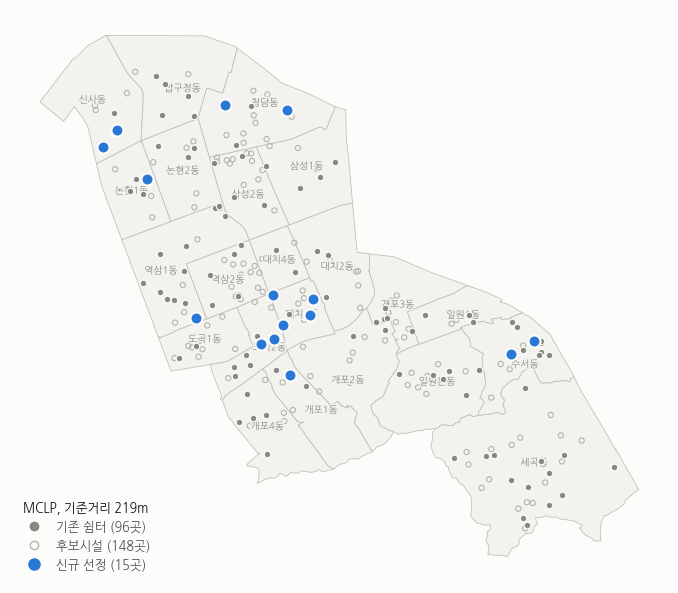

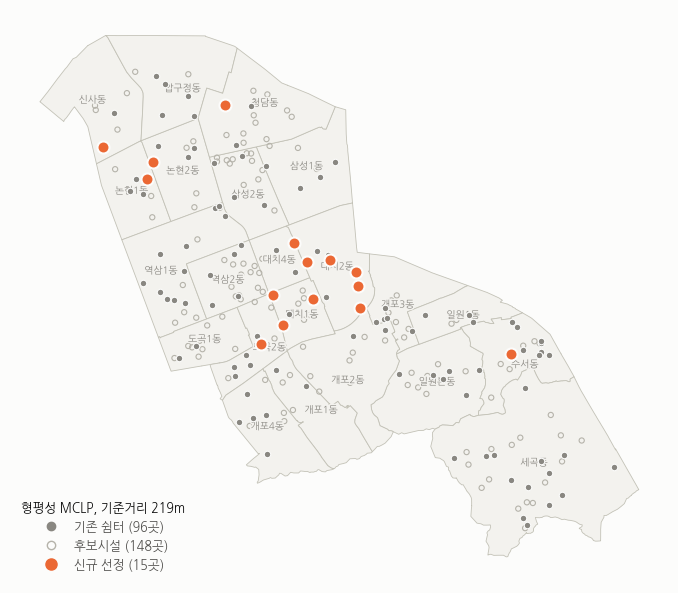

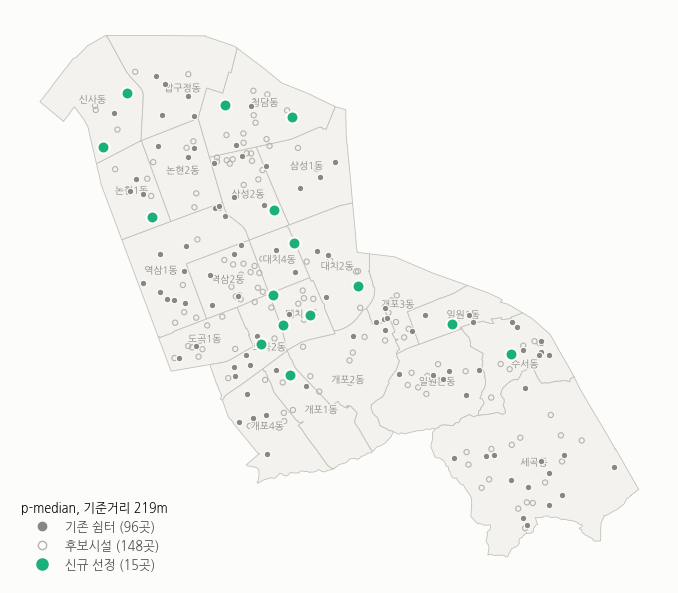

In [12]:
for model in MODELS:
    sel = cand_clean.iloc[selected[(model, P_MAP)]]
    fig, ax = plt.subplots(figsize=(8.5, 8.5))
    context_layers(ax)
    ax.scatter(sel.geometry.x, sel.geometry.y, s=75, color=MODEL_COLOR[model], edgecolors=SURFACE, linewidths=1.5, zorder=6)
    handles = context_handles() + [
        Line2D([], [], marker="o", linestyle="", markersize=8, color=MODEL_COLOR[model], label=f"신규 선정 ({P_MAP}곳)")]
    ax.legend(handles=handles, title=f"{model}, 기준거리 {COVERAGE_DISTANCE_M}m", frameon=False,
              loc="lower left", fontsize=9, title_fontsize=9, labelcolor=INK_SUB)
    save(fig, f"02_선정입지_{MODEL_FILE[model]}_p{P_MAP}.png")
    plt.show()



# 보조 함수 : context_layers(ax), context_handles()
# cand_clean = candidate_clean 
# node = network_node
# snap_m = snap_distance_m

# MODEL_COLOR = {"MCLP": BLUE, "형평성 MCLP": ORANGE, "p-median": AQUA}
# SURFACE, LAND, BORDER, GRID = "#fcfcfb", "#f3f2ee", "#c3c2b7", "#e1e0d9"
# MODELS = ["MCLP", "형평성 MCLP", "p-median"]
# MODEL_COLOR = {"MCLP": BLUE, "형평성 MCLP": ORANGE, "p-median": AQUA}
# MODEL_FILE = {"MCLP": "MCLP", "형평성 MCLP": "형평성MCLP", "p-median": "p-median"}

## 7. 세 모형 공통 선정 입지

세 모형이 모두 고른 자리는 목적함수를 바꿔도 남는 자리라서 우선 권고안 후보가 된다. 겹친 모형 수가 많을수록 진하게 칠했다.

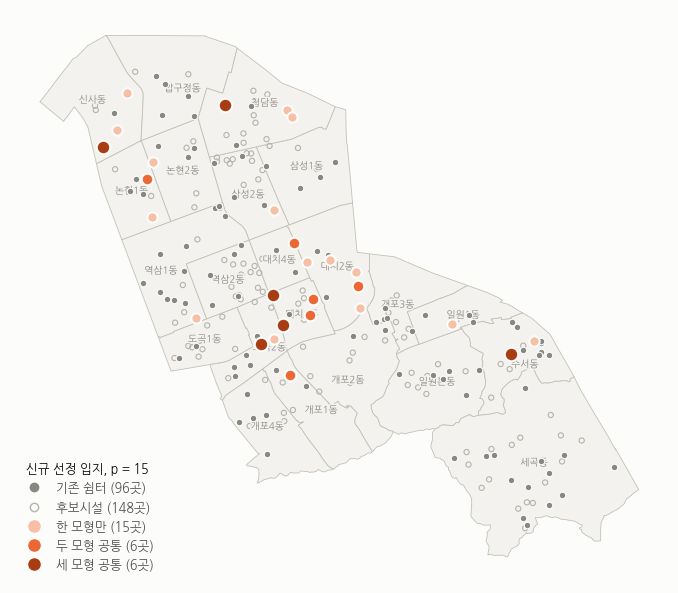

MCLP ∩ 형평성 MCLP: 8곳 / 15곳
MCLP ∩ p-median: 8곳 / 15곳
형평성 MCLP ∩ p-median: 8곳 / 15곳


,시설명,시설유형,MCLP,형평성 MCLP,p-median,모형수
candidate_id,,,,,,
C008,강남상가아파트,경로당,True,True,True,3
C024,대림아크로빌아파트,경로당,True,True,True,3
C040,동부센트레빌아파트,경로당,True,True,True,3
C058,롯데캐슬리베아파트,경로당,True,True,True,3
C080,수서7단지아파트,경로당,True,True,True,3
C112,청담,경로당,True,True,True,3
C033,대치포스코더샵,경로당,False,True,True,2
C048,래미안대치팰리스2단지아파트,경로당,True,True,False,2
C072,선경아파트,경로당,True,False,True,2


In [13]:
votes = Counter(j for m in MODELS for j in selected[(m, P_MAP)])
style = {3: (ORANGE_RAMP[2], 95, "세 모형 공통"), 2: (ORANGE_RAMP[1], 70, "두 모형 공통"), 1: (ORANGE_RAMP[0], 55, "한 모형만")}

fig, ax = plt.subplots(figsize=(8.5, 8.5))
context_layers(ax)
handles = context_handles()
for k in (1, 2, 3):
    idx = [j for j, v in votes.items() if v == k]
    color, size, label = style[k]
    if idx:
        pts = cand_clean.iloc[idx]
        ax.scatter(pts.geometry.x, pts.geometry.y, s=size, color=color, edgecolors=SURFACE, linewidths=1.5, zorder=5 + k)
    handles.append(Line2D([], [], marker="o", linestyle="", markersize=8, color=color, label=f"{label} ({len(idx)}곳)"))
ax.legend(handles=handles, title=f"신규 선정 입지, p = {P_MAP}", frameon=False,
          loc="lower left", fontsize=9, title_fontsize=9, labelcolor=INK_SUB)
save(fig, f"03_공통_선정입지_p{P_MAP}.png")
plt.show()

sets = {m: set(selected[(m, P_MAP)]) for m in MODELS}
for a, b in [("MCLP", "형평성 MCLP"), ("MCLP", "p-median"), ("형평성 MCLP", "p-median")]:
    print(f"{a} ∩ {b}: {len(sets[a] & sets[b])}곳 / {P_MAP}곳")

common = cand_clean.loc[list(votes), ["candidate_id", "시설명", "시설유형"]].copy()
for m in MODELS:
    common[m] = common.index.isin(sets[m])
common["모형수"] = common[MODELS].sum(axis=1)
common = common.sort_values(["모형수", "candidate_id"], ascending=[False, True])
display(common.set_index("candidate_id"))

## 8. p별 선정 후보지

p를 늘릴 때 어떤 후보지가 처음 들어오고 계속 남는지 본다. 한 번이라도 선정된 후보지만 그렸고, 처음 선정된 p 순서로 위에서부터 놓았다.
점이 오른쪽 끝까지 이어지면 p가 커져도 빠지지 않는 안정적인 자리다. 세로 점선은 지도에 쓴 p다.

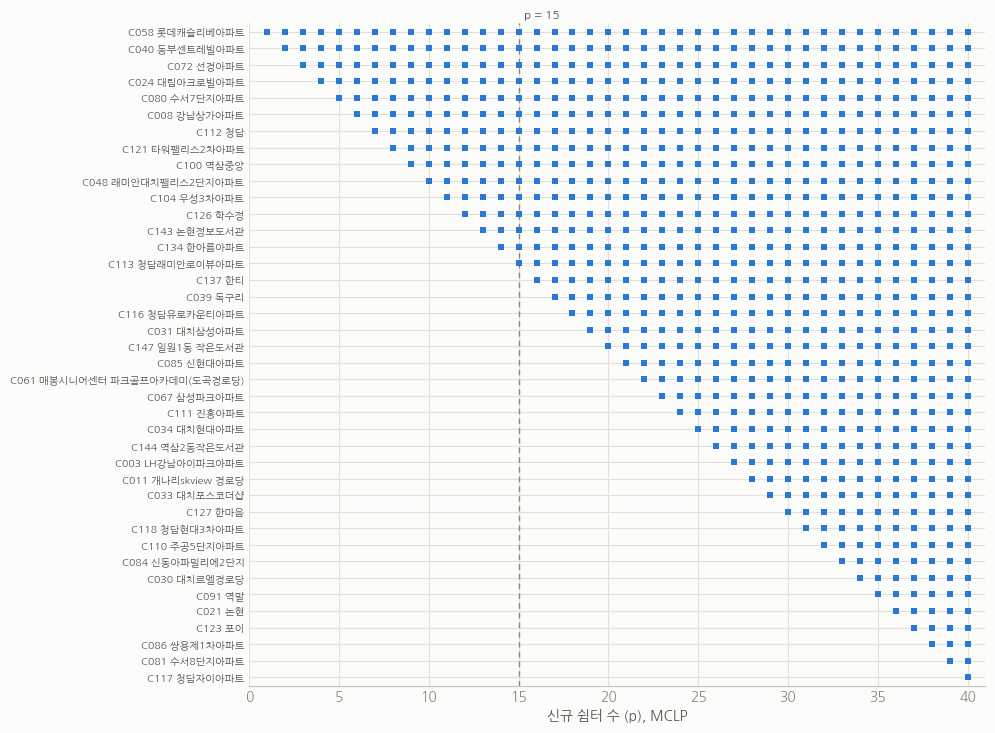

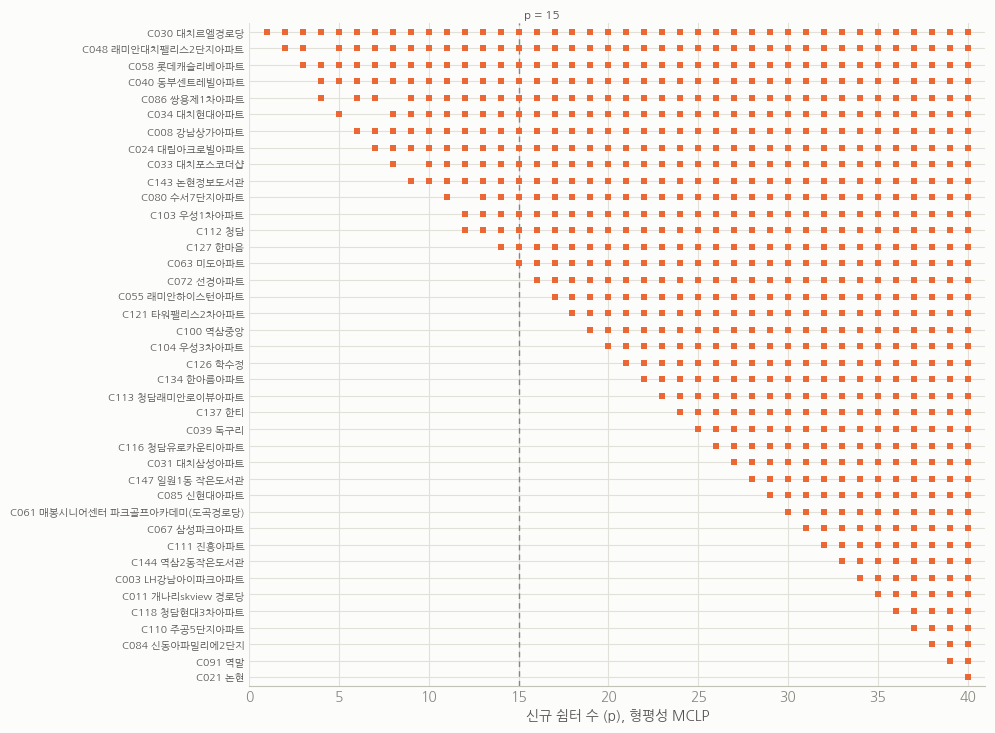

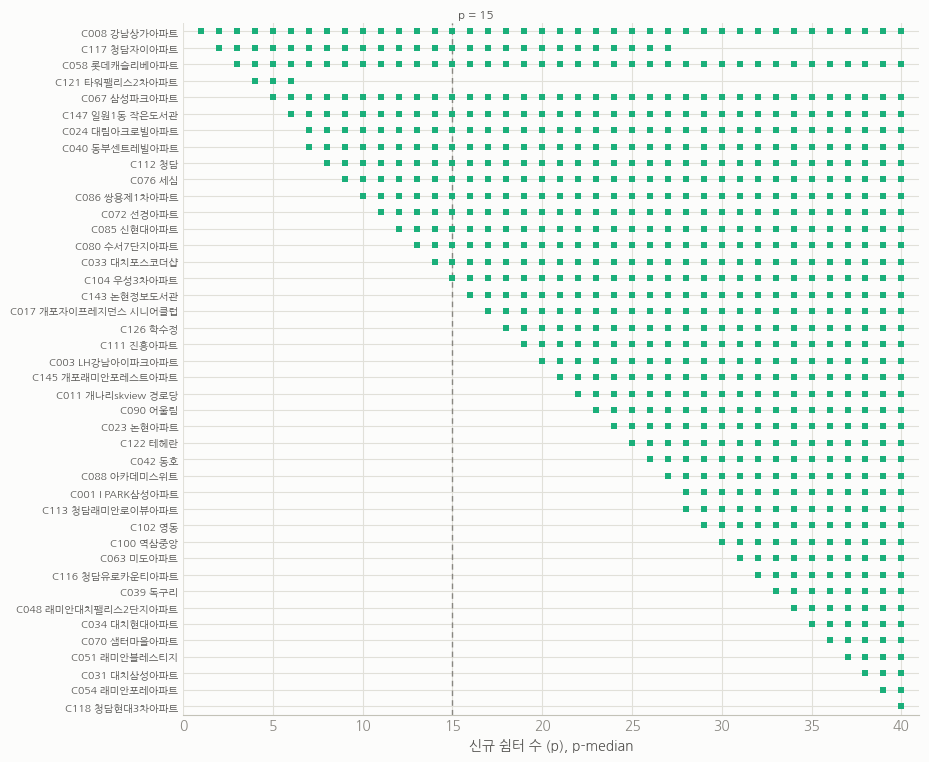

In [14]:
for model in MODELS:
    first = {}
    for p in range(1, P_MAX + 1):
        for j in selected[(model, p)]:
            first.setdefault(j, p)
    count = Counter(j for p in range(1, P_MAX + 1) for j in selected[(model, p)])
    order = sorted(first, key=lambda j: (first[j], -count[j]))
    row = {j: r for r, j in enumerate(order)}

    xs = [p for p in range(1, P_MAX + 1) for j in selected[(model, p)]]
    ys = [row[j] for p in range(1, P_MAX + 1) for j in selected[(model, p)]]

    fig, ax = plt.subplots(figsize=(9.5, max(4, 0.19 * len(order) + 1)))
    ax.scatter(xs, ys, s=16, marker="s", color=MODEL_COLOR[model], linewidths=0, zorder=3)
    ax.axvline(P_MAP, color=INK_MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
    ax.annotate(f"p = {P_MAP}", (P_MAP, 1), xycoords=("data", "axes fraction"), xytext=(4, 2),
                textcoords="offset points", fontsize=8.5, color=INK_SUB, va="bottom")
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(cand_clean.loc[order, "label"], fontsize=7.5)
    ax.set_ylim(len(order) - 0.5, -0.5)
    ax.set_xlim(0, P_MAX + 1)
    ax.set_xticks(range(0, P_MAX + 1, 5))
    ax.set_xlabel(f"신규 쉼터 수 (p), {model}")
    ax.spines["left"].set_visible(False)
    clean(ax, "both")
    save(fig, f"04_p별_선정후보지_{MODEL_FILE[model]}.png")
    plt.show()

## 9. p별 성과 곡선

세 모형의 해를 같은 세 지표로 잰다. 각 모형은 자기 목적함수에 해당하는 지표에서 가장 좋고, 나머지 지표에서 얼마나 손해를 보는지가 비교의 핵심이다.
MCLP는 커버율, 형평성 MCLP는 최저 행정동 커버율, p-median은 평균 보행거리가 자기 지표다. p = 0은 기존 쉼터만 있는 상태다.

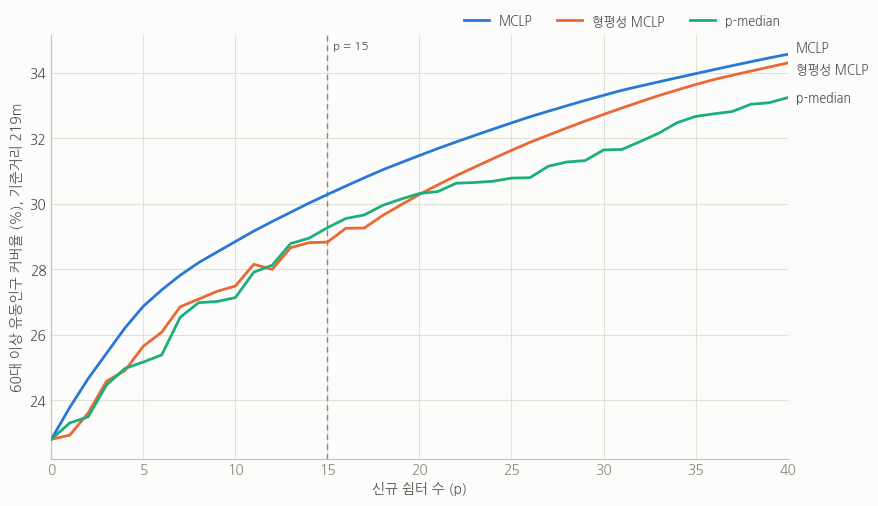

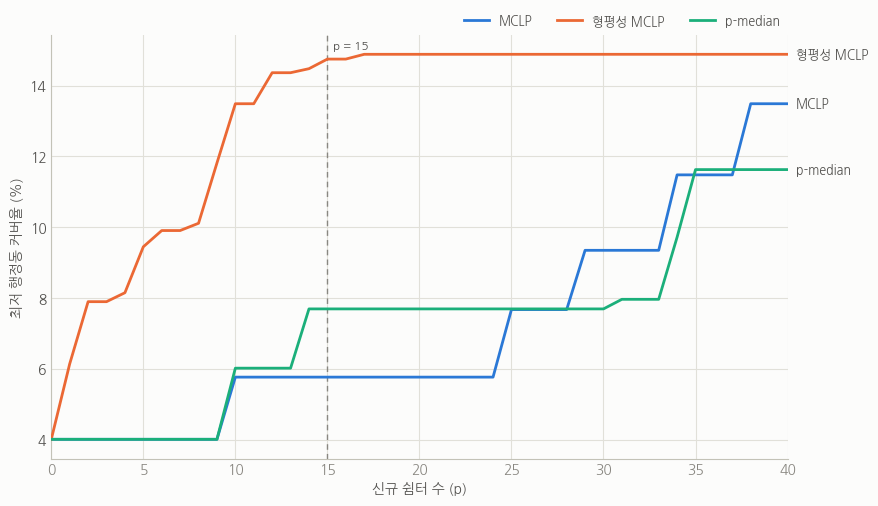

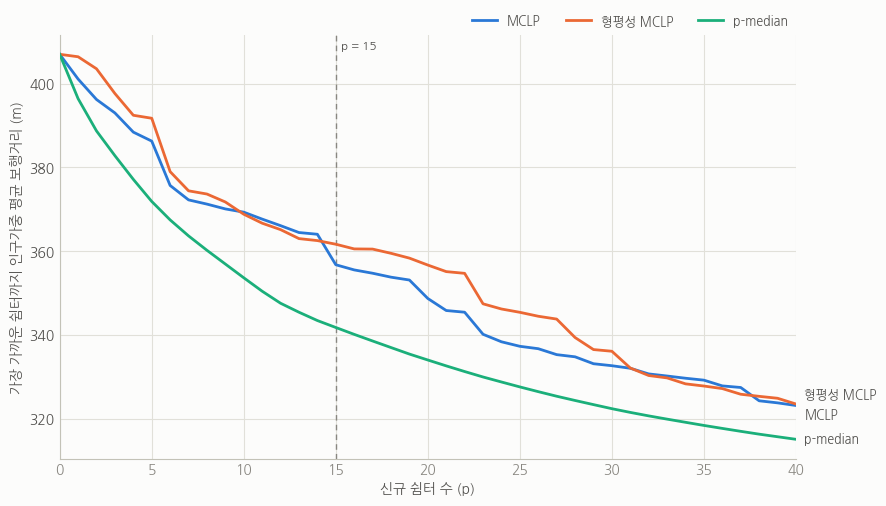

In [15]:
def plot_curves(col, ylabel, name):
    fig, ax = plt.subplots(figsize=(9.5, 5.5))
    ends = []
    for model in MODELS:
        s = metrics[metrics["model"] == model].set_index("p")[col]
        ax.plot(s.index, s.to_numpy(), color=MODEL_COLOR[model], linewidth=2, zorder=3)
        ends.append(s.iloc[-1])
    ax.axvline(P_MAP, color=INK_MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
    ax.annotate(f"p = {P_MAP}", (P_MAP, 1), xycoords=("data", "axes fraction"), xytext=(4, -4),
                textcoords="offset points", fontsize=8.5, color=INK_SUB, va="top")
    ax.set_xlim(0, P_MAX)
    ax.set_xticks(range(0, P_MAX + 1, 5))
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi)
    for model, y in zip(MODELS, spread(ends, (hi - lo) * 0.05)):
        ax.annotate(model, (P_MAX, y), xytext=(6, 0), textcoords="offset points", va="center",
                    fontsize=9, color=INK_SUB, annotation_clip=False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,g}"))   # 12.5 같은 눈금을 반올림하지 않는다
    ax.set_xlabel("신규 쉼터 수 (p)")
    ax.set_ylabel(ylabel)
    clean(ax, "both")
    legend_top(ax, [Line2D([], [], color=MODEL_COLOR[m], linewidth=2, label=m) for m in MODELS])
    save(fig, name)
    plt.show()


plot_curves("coverage_pct", f"60대 이상 유동인구 커버율 (%), 기준거리 {COVERAGE_DISTANCE_M}m", "05_p별_커버율.png")
plot_curves("min_dong_pct", "최저 행정동 커버율 (%)", "06_p별_최저동커버율.png")
plot_curves("mean_dist_m", "가장 가까운 쉼터까지 인구가중 평균 보행거리 (m)", "07_p별_평균거리.png")

## 10. 결과 저장

저장하는 표는 강남구 단위 지표와 후보시설 목록(공개 자료)뿐이다. 격자 단위 값은 저장하지 않는다.

In [16]:
if SAVE:
    metrics.drop(columns="covered_people").to_csv(OUT / "모형별_p별_지표.csv", index=False, encoding="utf-8-sig")
    picks = pd.DataFrame([{"model": m, "p": p, "candidate_id": cand_clean.at[j, "candidate_id"]}
                          for (m, p), sel in selected.items() for j in sel])
    picks = picks.merge(cand_clean[["candidate_id", "시설명", "시설유형", "위도", "경도"]], on="candidate_id")
    picks.to_csv(OUT / "p별_선정후보지.csv", index=False, encoding="utf-8-sig")
    common.to_csv(OUT / f"공통_선정입지_p{P_MAP}.csv", index=False, encoding="utf-8-sig")
    print("저장 위치:", OUT)

저장 위치: gangnam_output


## 실제 자료로 돌릴 때

- `SAFE_ZONE = True`로 바꾸고 `FLOW_PATH`, `INPUT`, `STD_YM`을 확인한다. 폭염 분석이면 7~8월이 맞다.
- 반입할 파일은 이 노트북과 `GangnamBoundary` 다섯 개(.shp, .shx, .dbf, .prj, .cpg), `GangnamCoolingCenter.csv`, `GangnamCandidateFacility.csv`, `GangnamNetwork.csv`다. `GangnamPopulation.csv`는 모의 자료라서 반입하지 않는다.
- 안심구역에서는 서울 전체 유동인구 파일을 읽고 강남구 경계 안 격자만 남긴다. 성별ㆍ연령 파일 하나만 쓴다.
- 보행 네트워크가 강남구 경계에서 잘려 있어서 구 밖으로 잠깐 나갔다 들어오는 경로는 계산되지 않는다. 경계 가까운 수요지의 거리가 조금 길게 나올 수 있다.
- 지도에는 수요 격자를 그리지 않았다. 반출되는 그림에는 시설 위치와 행정동 경계만 있다.